# Homework 9


**Concepts covered:**

matplotlib, line charts, pie chart, histogram, scatterplot

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.



**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.


## Shared Imports

Run the cell below to import modules that will be used through out
this homework notebook. Do not import any other modules.
In particular, other charting modules such as Seaborn are not allowed.

In [1]:
# shared imports
import math
import numpy as np
import matplotlib.pyplot as plt


**NOTE: Use the appropriate and optimal ranges for the axis values so that the visualizations are not too small.**


**This homework is partially autograded. The plots will be manually graded so please allow some time for you to get a full score.**

**Problem 1 (review)**

**Concept:** *NumPy arrays, math functions*

**Task:**

Write three functions that generate numerical arrays using NumPy.

Each function takes three parameters:

* **start** – the starting value of the array

* **stop** – the ending value of the array (not inclusive)

* **steps** – the increment between values in the array (the step size used by `np.arange`)

Use `np.arange(start, stop, steps)` to generate the base array of values. Then apply the requested NumPy math function to the entire array.

**Functions to Implement:**

1. `generate_sine_wave(start, stop, steps)`

* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the sine of each value using `np.sin`.
* Return the array of sine values.
2. `generate_logs(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the natural logarithm of each value using `np.log`.
* Return the array of log values.
3. `generate_rounded(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Round each value using `np.round`.
* Return the rounded array.



In [2]:
# Your Solution
def generate_sine_wave(start, stop, steps):
    """Generate an array of sine values."""
    # Create array
    values = np.arange(start, stop, steps)
    # Calculate sine
    return np.sin(values)

def generate_logs(start, stop, steps):
    """Generate an array of natural logarithm values."""
    # Create array
    values = np.arange(start, stop, steps)
    # Calculate natural log
    return np.log(values)

def generate_rounded(start, stop, steps):
    """Generate an array of rounded values."""
    # Create array
    values = np.arange(start, stop, steps)
    # Round values
    return np.round(values)

**Problem 2 (review)**

**Concept:** *reading CSV file, create an np.array of numbers*

**Task:**

Write a function `read_csv_to_dict(filename)` that reads a CSV file and stores the data in a dictionary.

Your function should:
1. Open the CSV file.
2. Read the first row to obtain column headers.
3. Store each column of data as a NumPy array.
4. Use the column names as keys in the dictionary.
5. Return the dictionary.

Each key should correspond to one column in the CSV file.

Example structure:

```
{
   "open": np.array([...]),
   "close": np.array([...]),
   "volume": np.array([...])
}
```


In [3]:
#Your Solution
def read_csv_to_dict(filename):
    """Read a CSV file and store columns as NumPy arrays."""
    # Open file
    with open(filename, 'r') as file:
        # Get headers
        headers = file.readline().strip().split(',')
        # Create dictionary
        data = {header: [] for header in headers}
        # Read rows
        for line in file:
            values = line.strip().split(',')
            # Store values
            for header, value in zip(headers, values):
                data[header].append(value)
    # Convert columns to arrays
    for header in data:
        try:
            # Convert to numbers
            data[header] = np.array(data[header], dtype=float)
        except ValueError:
            # Keep text as strings
            data[header] = np.array(data[header])
    return data

**Problem 3**

**Concepts:** *matplotlib, plt line*

**Task:**

Use NumPy and Matplotlib to generate and plot sine and cosine waves.

Complete the following steps:

1. Create a range of values from **0 to 20** using `np.arange`.
2. Compute:
* the sine wave
* the cosine wave

Create four plots:
1. Plot the **sine wave** by itself.
2. Plot the **cosine wave** by itself.
3. Plot **both waves together on the same chart** with a legend.
4. Compute the **ratio of sine to cosine** and plot it.

Each chart should include a **title**, and the combined chart should include a **legend**.


**Plot 1:**

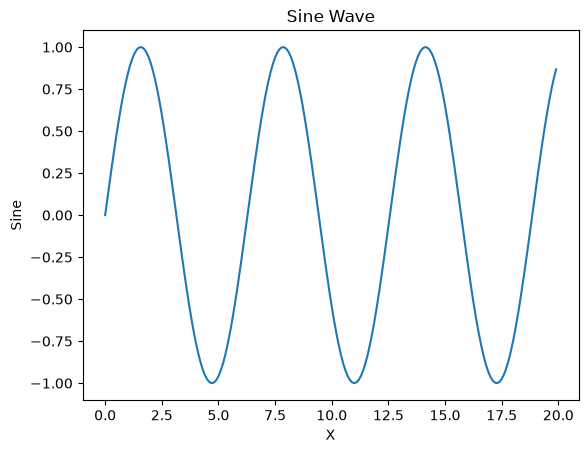

In [4]:
#Your Solution
# Create values
x = np.arange(0, 20, 0.1)
sine = np.sin(x)

# Plot sine
plt.plot(x, sine)
plt.title("Sine Wave")
plt.xlabel("X")
plt.ylabel("Sine")
plt.show()

**Plot 2:**

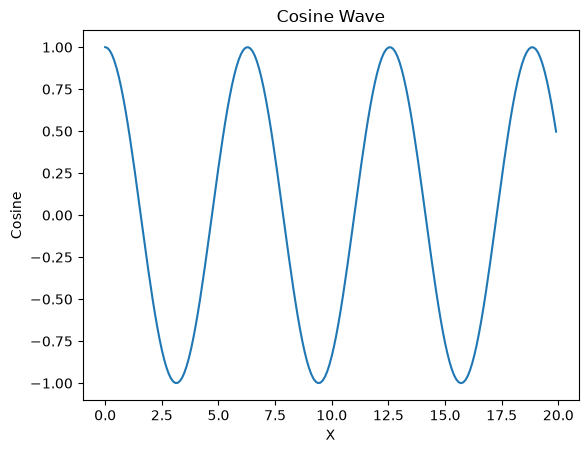

In [5]:
#Your Solution
# Calculate cosine
cosine = np.cos(x)

# Plot cosine
plt.plot(x, cosine)
plt.title("Cosine Wave")
plt.xlabel("X")
plt.ylabel("Cosine")
plt.show()

**Plot 3:**

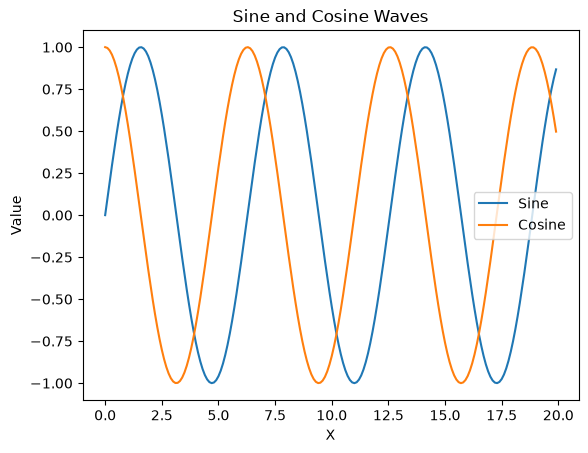

In [6]:
#Your Solution
# Plot both waves
plt.plot(x, sine, label="Sine")
plt.plot(x, cosine, label="Cosine")

# Add labels and legend
plt.title("Sine and Cosine Waves")
plt.xlabel("X")
plt.ylabel("Value")
plt.legend()
plt.show()

**Plot 4:**

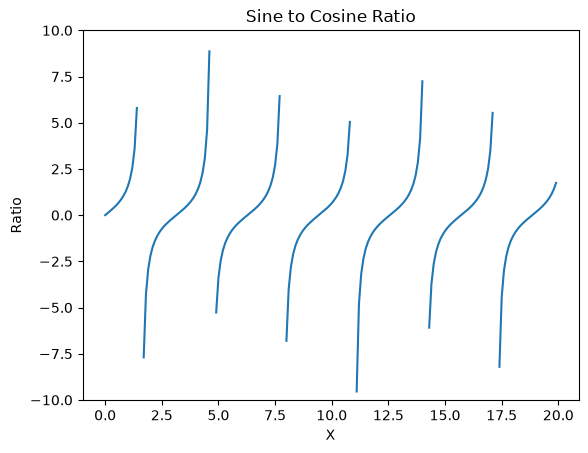

In [7]:
#Your Solution
# Calculate ratio
ratio = sine / cosine

# Remove values near undefined points
ratio[np.abs(cosine) < 0.1] = np.nan

# Plot ratio
plt.plot(x, ratio)
plt.title("Sine to Cosine Ratio")
plt.xlabel("X")
plt.ylabel("Ratio")
plt.ylim(-10, 10)
plt.show()

**Problem 4**

**Concepts:** *matplotlib, bar chart*

**Task:**

Use the provided lists representing fruit consumption over several days.

Create the following visualizations:

1. A **stacked bar chart** showing strawberry and banana consumption.
2. Two **separate bar charts using subplots**:
* One chart for strawberries (red)
* One chart for bananas (yellow)

Each chart should include:
* a title
* a legend

In [8]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]

**Plot 1: Stacked Bar Chart**

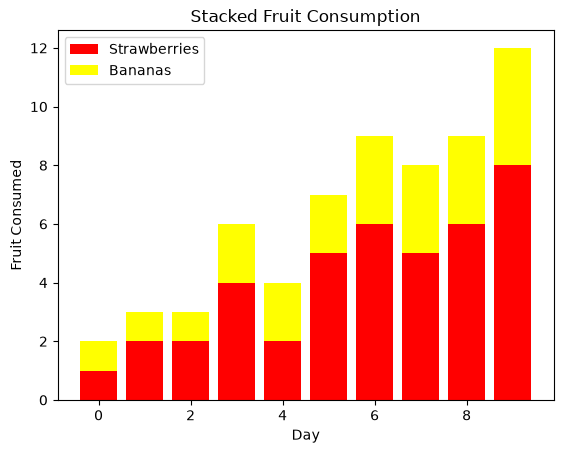

In [9]:
#Your Solution
# Plot strawberries
plt.bar(days, strawberries, color='red', label='Strawberries')

# Stack bananas on top
plt.bar(days, bananas, bottom=strawberries, color='yellow', label='Bananas')

# Add labels
plt.title('Stacked Fruit Consumption')
plt.xlabel('Day')
plt.ylabel('Fruit Consumed')
plt.legend()
plt.show()

**Plot 2: Separate Bar Chart**

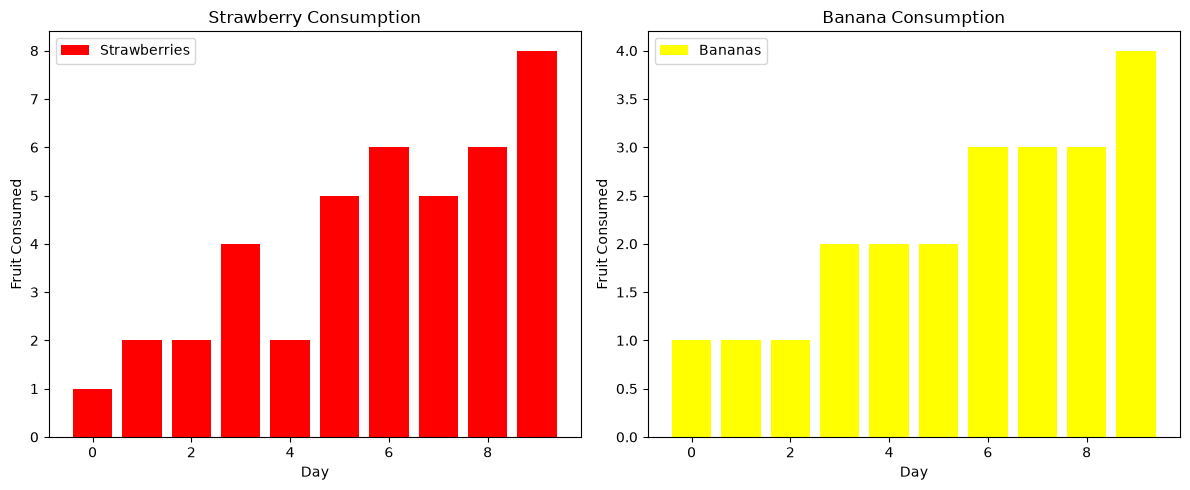

In [10]:
#Your Solution
# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot strawberries
ax[0].bar(days, strawberries, color='red', label='Strawberries')
ax[0].set_title('Strawberry Consumption')
ax[0].set_xlabel('Day')
ax[0].set_ylabel('Fruit Consumed')
ax[0].legend()

# Plot bananas
ax[1].bar(days, bananas, color='yellow', label='Bananas')
ax[1].set_title('Banana Consumption')
ax[1].set_xlabel('Day')
ax[1].set_ylabel('Fruit Consumed')
ax[1].legend()

plt.tight_layout()
plt.show()

**Problem 5**

**Concepts:** *matplotlib, bar chart*

**Task:**

Using the same fruit consumption data from Problem 4, create a **grouped bar chart**.

Your chart should:
1. Display strawberries (red) and bananas (yellow) side-by-side for each day.
2. Use a bar width to offset the second set of bars.
3. Label the x-axis with the day numbers.
4. Include:
    * axis labels
    * a title
    * a legend

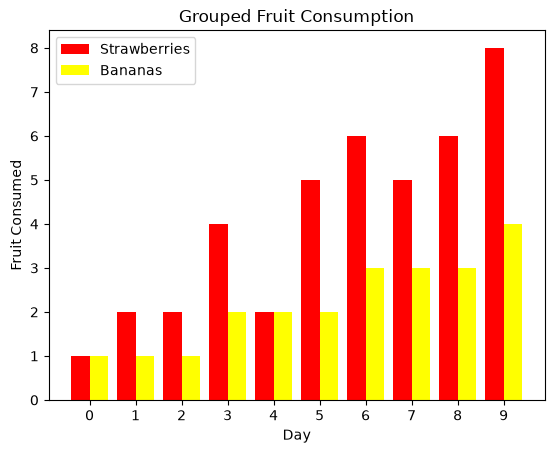

In [11]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]

#Your Solution
# Set bar width
width = 0.4
x = np.array(days)

# Plot strawberries
plt.bar(x - width/2, strawberries, width, color='red', label='Strawberries')

# Plot bananas
plt.bar(x + width/2, bananas, width, color='yellow', label='Bananas')

# Add labels
plt.xlabel('Day')
plt.ylabel('Fruit Consumed')
plt.title('Grouped Fruit Consumption')
plt.xticks(x)
plt.legend()
plt.show()

**Problem 6**

**Concepts:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that displays the points of a **unit circle**.

Steps:

1. Generate `x` values between **0 and 1**.
2. Compute the corresponding `y` values using the circle equation:

$$y = sqrt(1 − x²)$$

3. Reflect the points across all four quadrants so that the full circle is drawn.
4. Plot the points using `plt.scatter`.

Set the figure size to **(5,5)** so the circle appears correctly proportioned.

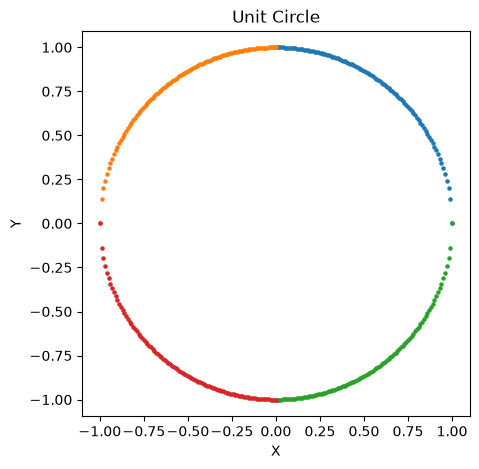

In [12]:
#Your Solution
# Generate x and y values
x = np.arange(0, 1.01, 0.01)
y = np.sqrt(1 - x**2)

# Set figure size
plt.figure(figsize=(5, 5))

# Plot all four quadrants
plt.scatter(x, y, s=5)
plt.scatter(-x, y, s=5)
plt.scatter(x, -y, s=5)
plt.scatter(-x, -y, s=5)

# Add labels
plt.title('Unit Circle')
plt.xlabel('X')
plt.ylabel('Y')
plt.axis('equal')
plt.show()

**Problem 7**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot using the provided `x_data` and `y_data`.

Plot the data **four different ways on the same chart**:
1. Original values `(x, y)`
2. Horizontal reflection `(-x, y)`
3. Vertical reflection `(x, -y)`
4. Reflection across both axes `(-x, -y)`

Add:
* a legend
* a chart title

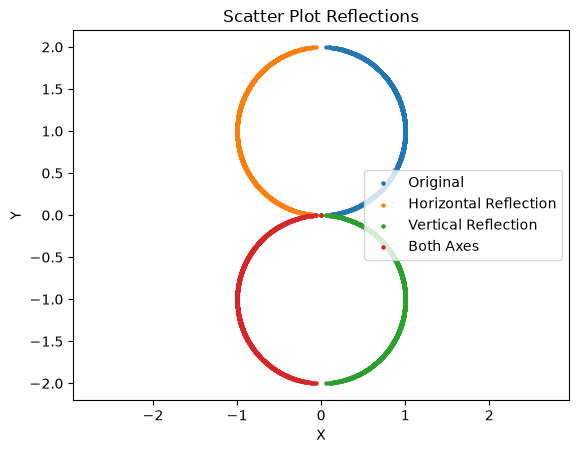

In [13]:
# STARTER CODE; DO NOT CHANGE

y_data = [i / 500 for i in range(1000)]
x_data = [math.sqrt(1 - (y - 1)**2) for y in y_data]


#Your Solution
# Convert lists to arrays
x = np.array(x_data)
y = np.array(y_data)

# Plot original points
plt.scatter(x, y, s=5, label='Original')

# Reflect horizontally
plt.scatter(-x, y, s=5, label='Horizontal Reflection')

# Reflect vertically
plt.scatter(x, -y, s=5, label='Vertical Reflection')

# Reflect across both axes
plt.scatter(-x, -y, s=5, label='Both Axes')

# Add title and legend
plt.title('Scatter Plot Reflections')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.axis('equal')
plt.show()

**Problem 8**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot that produces a **spiral or tornado-like pattern**.

Steps:
1. Generate a list of radius values that gradually increase so the points move farther away from the center over time.
2. Use a sequence of angle values so that each point rotates a little more than the previous one.
3. Compute the x-coordinates by multiplying each radius value by the cosine of its angle.
4. Compute the y-coordinates by multiplying each radius value by the sine of its angle.
5. Use plt.scatter() to plot the (x, y) points.
6. Add a title to the chart.



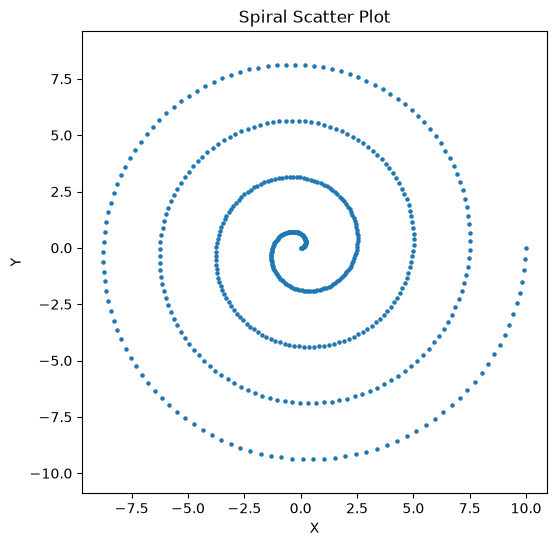

In [14]:
#Your Solution
# Generate radius and angle values
radius = np.linspace(0, 10, 500)
angle = np.linspace(0, 8 * np.pi, 500)

# Calculate coordinates
x = radius * np.cos(angle)
y = radius * np.sin(angle)

# Plot spiral
plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=5)

# Add title
plt.title('Spiral Scatter Plot')
plt.xlabel('X')
plt.ylabel('Y')
plt.axis('equal')
plt.show()

**Problem 9**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Using the helper function `read_csv_to_dict`, read a dataset stored in `p9_data.csv` containing two numerical variables.

The dataset contains the following columns:

* `dataset` (string label)

* `x` (numerical variable)

* `y` (numerical variable)

Create a scatter plot using the **x** and **y** values for the dataset.

Your plot should include:
* x-axis label
* y-axis label
* title

The goal is to visualize how the two variables relate to each other.

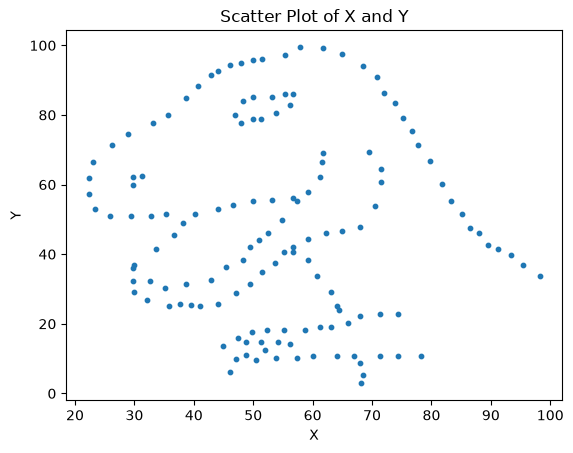

In [15]:
#Your Solution
# Read CSV file
data = read_csv_to_dict('p9_data.csv')

# Get x and y values
x = data['x']
y = data['y']

# Plot data
plt.scatter(x, y, s=10)

# Add labels
plt.title('Scatter Plot of X and Y')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

**Problem 10**

**Concepts:** *reading CSV file, line graph*

**Task:**

Write a function:

`create_line_graph(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Verify the specified column exists.
3. Convert the column values to floats.
4. Plot the values as a **line graph**.

Your graph should include:
* a title
* x-axis labeled **Day Number**
* y-axis labeled with the column name

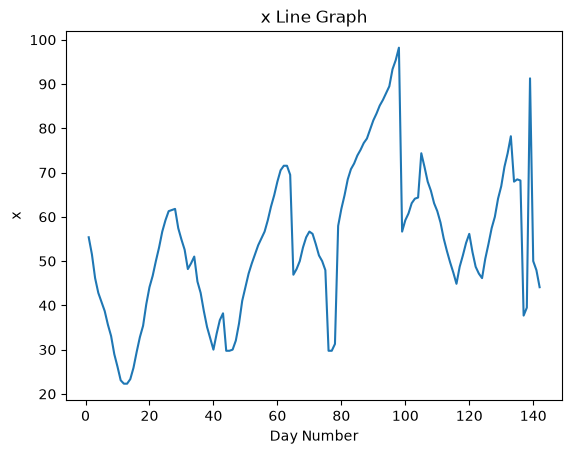

In [16]:
#Your Solution
def create_line_graph(filename, column_name):
    """Create a line graph from a CSV column."""
    # Read CSV file
    data = read_csv_to_dict(filename)

    # Check column exists
    if column_name not in data:
        print("Column not found")
        return

    # Convert to floats
    values = np.array(data[column_name], dtype=float)

    # Create day numbers
    days = np.arange(1, len(values) + 1)

    # Plot line graph
    plt.plot(days, values)

    # Add labels
    plt.title(column_name + ' Line Graph')
    plt.xlabel('Day Number')
    plt.ylabel(column_name)
    plt.show()
create_line_graph('p9_data.csv', 'x')

**Problem 11**

**Concepts:** *reading CSV file, histogram*

**Task:**

Write a function:

`create_histogram(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Create a histogram of the data.

Requirements:
* Use **at least 10 bins**.
* Add a title showing the column name.

The histogram should display the distribution of values in the selected column.

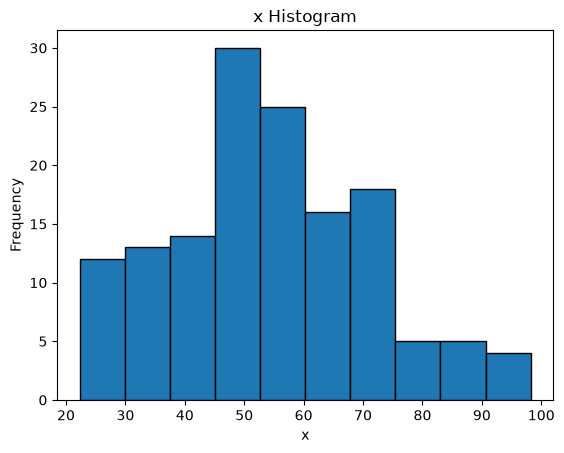

In [17]:
#Your Solution
def create_histogram(filename, column_name):
    """Create a histogram from a CSV column."""
    # Read CSV file
    data = read_csv_to_dict(filename)

    # Convert to numbers
    values = np.array(data[column_name], dtype=float)

    # Create histogram
    plt.hist(values, bins=10, edgecolor='black')

    # Add labels
    plt.title(column_name + ' Histogram')
    plt.xlabel(column_name)
    plt.ylabel('Frequency')
    plt.show()
create_histogram('p9_data.csv', 'x')

**Problem 12**

**Concepts:** *reading CSV file, pie chart*

**Task:**

Write a function:

`create_pie_chart(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Compute the **mean value** of the column.
4. Determine:
* the percentage of values **greater than the mean**
* the percentage **less than or equal to the mean**

Create a pie chart displaying these two proportions.

Include:
* labels
* percentages
* chart title

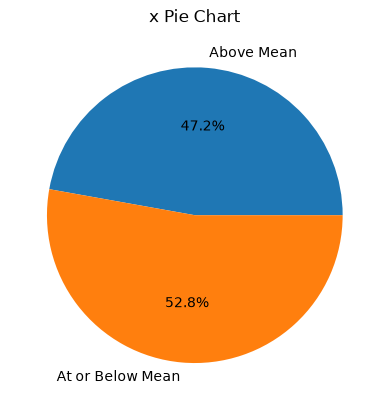

In [18]:
#Your Solution
def create_pie_chart(filename, column_name):
    """Create a pie chart comparing values to the mean."""
    # Read CSV file
    data = read_csv_to_dict(filename)

    # Convert to numbers
    values = np.array(data[column_name], dtype=float)

    # Calculate mean
    mean = np.mean(values)

    # Count values
    above = np.sum(values > mean)
    below = np.sum(values <= mean)

    # Create pie chart
    plt.pie([above, below],
            labels=['Above Mean', 'At or Below Mean'],
            autopct='%1.1f%%')

    # Add title
    plt.title(column_name + ' Pie Chart')
    plt.show()
create_pie_chart('p9_data.csv', 'x')

**Problem 13**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Write a function:

`create_scatter_plot(filename, x_column, y_column)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Extract the specified columns.
3. Convert the values to floats.
4. Create a scatter plot showing the relationship between the two variables.

Include:
* x-axis label
* y-axis label
* title

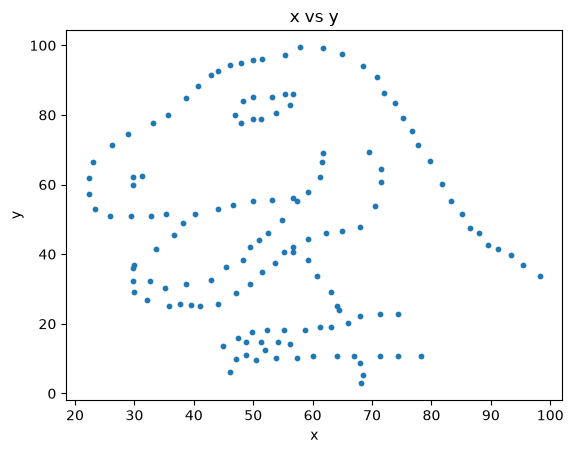

In [19]:
#Your Solution
def create_scatter_plot(filename, x_column, y_column):
    """Create a scatter plot from two CSV columns."""
    # Read CSV file
    data = read_csv_to_dict(filename)

    # Get columns and convert to floats
    x = np.array(data[x_column], dtype=float)
    y = np.array(data[y_column], dtype=float)

    # Create scatter plot
    plt.scatter(x, y, s=10)

    # Add labels
    plt.title(x_column + ' vs ' + y_column)
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.show()
create_scatter_plot('p9_data.csv', 'x', 'y')